# Linear probing on frozen video features
@author = Merbouche Mouloud


This notebook runs the linear probing pipeline end to end on synthetic features that have the same shape as the real ones: clips x 16 frames x 768 dimensions, 174 classes.

The synthetic features only validate the pipeline. Their scores carry no scientific meaning. They will be replaced by frozen DINOv3 and V-JEPA 2.1 features extracted from Something-Something V2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"

synth features

In [2]:
n_classes = 174  # SSv2
n_frames = 16
dim = 768  # ViT-B

# one random prototype per class, same on all the frames, + gaussian noise
# 0.06 = how far apart the classes are (bigger -> easier)
rng = np.random.default_rng(0)
protos = 0.06 * rng.standard_normal((n_classes, dim), dtype=np.float32)
y = np.repeat(np.arange(n_classes), 20)  # 20 clips per class
y = rng.permutation(y)
X = rng.standard_normal((len(y), n_frames, dim), dtype=np.float32)
X += protos[y][:, None, :]
print(X.shape, y.shape)

(3480, 16, 768) (3480,)


split and normalization

In [ ]:
# 60 / 20 / 20
perm = np.random.default_rng(0).permutation(len(y))
n = int(0.2 * len(y))
test_idx = perm[:n]
val_idx = perm[n:2 * n]
train_idx = perm[2 * n:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# normalize each dim, with the train stats only
mu = X_train.mean(axis=(0, 1))
std = X_train.std(axis=(0, 1)) + 1e-6
X_train = (X_train - mu) / std
X_val = (X_val - mu) / std
X_test = (X_test - mu) / std

print(X_train.shape, X_val.shape, X_test.shape)

(2088, 16, 768) (696, 16, 768) (696, 16, 768)


In [4]:
class LinearProbe(nn.Module):
    def __init__(self, dim, n_classes):
        super().__init__()
        self.fc = nn.Linear(dim, n_classes)

    def forward(self, x):
        # x: (B, T, D) -> mean over the frames
        return self.fc(x.mean(dim=1))

In [ ]:
epochs = 30
bs = 256
lr = 1e-3


def predict(model, X):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = torch.from_numpy(X[i:i + bs]).to(device)
            preds.append(model(xb).argmax(dim=1).cpu())
    return torch.cat(preds).numpy()


def train(seed):
    torch.manual_seed(seed)
    model = LinearProbe(dim, n_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    Xtr = torch.from_numpy(X_train)
    ytr = torch.from_numpy(y_train)
    losses, val_accs = [], []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(ytr))
        tot = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            xb, yb = Xtr[idx].to(device), ytr[idx].to(device)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(idx)
        sched.step()
        losses.append(tot / len(ytr))
        val_accs.append((predict(model, X_val) == y_val).mean())
    return model, losses, val_accs

## Training curves

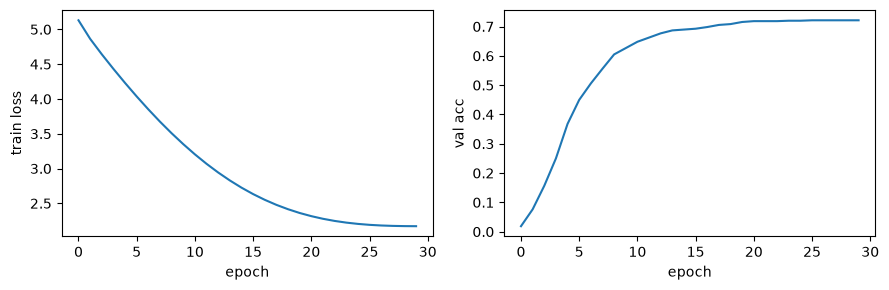

val acc: 0.721


In [6]:
model, losses, val_accs = train(0)

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1)
plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("train loss")
plt.subplot(1, 2, 2)
plt.plot(val_accs)
plt.xlabel("epoch")
plt.ylabel("val acc")
plt.tight_layout()
plt.show()

print(f"val acc: {val_accs[-1]:.3f}")

resultats sur le test

In [7]:
accs, class_accs = [], []
for seed in [0, 1, 2]:
    model, _, _ = train(seed)
    pred = predict(model, X_test)
    accs.append((pred == y_test).mean())
    # mean per class acc
    class_accs.append(np.mean([(pred[y_test == c] == c).mean() for c in np.unique(y_test)]))

# baseline: always predict the most frequent class of the train set
maj = np.bincount(y_train).argmax()

print(f"chance: {1 / n_classes:.3f}")
print(f"majority class: {(y_test == maj).mean():.3f}")
print(f"linear probe: {np.mean(accs):.3f} +- {np.std(accs):.3f}")
print(f"mean per class: {np.mean(class_accs):.3f} +- {np.std(class_accs):.3f}")

chance: 0.006
majority class: 0.000
linear probe: 0.773 +- 0.008
mean per class: 0.798 +- 0.005


order of frames

The probe averages the frames, so shuffling them should not change the predictions (it should with a temporal head).

In [8]:
shuf = np.random.default_rng(0).permutation(n_frames)
same = predict(model, X_test) == predict(model, X_test[:, shuf])
print(same.mean())

1.0


TODO

- Replace the synthetic features with frozen features extracted from Something-Something V2: V-JEPA 2.1 on the whole clip, V-JEPA 2.1 frame by frame, and DINOv3 frame by frame.
- Add temporal heads (1D temporal convolution, self-attention) and an order-blind MLP of the same size as a control.